In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import s3fs
import rioxarray as rio
import xarray as xr
import os
from shapely.geometry import Polygon
from shapely.plotting import plot_polygon

# Xarray dark mode hack
from IPython.display import HTML, display

display(HTML("""
<style>
    .xr-wrap {
        --xr-background-color-row-odd: rgba(100, 100, 100, 0.10) !important;
        --xr-background-color-row-even: rgba(30, 30, 30, 0.10) !important;
    }
</style>
"""))

In [2]:
fs = s3fs.S3FileSystem(
    key=os.environ["AWS_ACCESS_KEY_ID"],
    secret=os.environ["AWS_SECRET_ACCESS_KEY"],
    client_kwargs={"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    config_kwargs={
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
                }
)

storage_options = {
    "client_kwargs": {"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    "config_kwargs": {
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
    },
}

In [4]:
velocity = xr.open_dataset('s3://gaia/cjense/data/velocity/ZI_79N_velseries_combined_2000_2025.zarr', storage_options=storage_options, consolidated=False)
basins = gpd.read_file("/Users/cjense/Desktop/phd/data/Greenland Basins/Greenland_Basins_PS_v1.4.2.shp")

In [5]:
velocity = velocity.rio.write_crs('EPSG:3413')
velocity['VelocityMap']

<xarray.DataArray 'VelocityMap' (time: 545, band: 3, y: 1201, x: 801)> Size: 6GB
[1572871635 values with dtype=float32]
Coordinates:
  * time         (time) datetime64[ns] 4kB 2000-06-15T12:00:00 ... 2025-12-21...
  * band         (band) <U2 24B 'vx' 'vy' 'vv'
    _FillValue   (band) float64 24B ...
  * y            (y) float64 10kB -9.8e+05 -9.802e+05 ... -1.22e+06 -1.22e+06
  * x            (x) float64 6kB 4e+05 4.002e+05 4.004e+05 ... 5.598e+05 5.6e+05
    spatial_ref  int64 8B 0
    name         <U4 16B ...

In [6]:
zibasin = basins.loc[basins['NAME']=='ZACHARIAE_ISSTROM']
basin79n = basins.loc[basins['NAME']=='NIOGHALVFJERDSFJORDEN']
basins

,SUBREGION1,NAME,GL_TYPE,geometry
0,NW,UMIAMMAKKU_ISBRAE,TW,"POLYGON ((-250013.97 -1962482.806, -250392.427..."
1,CE,GEIKIE_UNNAMED_VESTFORD_S,TW,"POLYGON ((669064.856 -2093802.344, 668921.855 ..."
2,CW,RINK_ISBRAE,TW,"POLYGON ((245236.056 -1890271.273, 242838.452 ..."
3,CW,KANGERLUSSUUP_SERMERSUA,TW,"POLYGON ((245014.582 -1891216.649, 240674.78 -..."
4,CW,CW_NONAME3,LT,"POLYGON ((-196828.245 -2054377.448, -197638.91..."
...,...,...,...,...
255,CE,ICE_CAPS_CE,TW,"MULTIPOLYGON (((480453.985 -2471075.871, 48051..."
256,SE,GLACIERDEFRANCE,TW,"POLYGON ((417931.72 -2529065.683, 418087.619 -..."
257,SE,KNUD-RASMUSSEN,TW,"POLYGON ((408724.018 -2578806.113, 409354.054 ..."
258,SE,NIGERTULUUP_KATTILERTARPIA,TW,"POLYGON ((429219.393 -2549303.299, 429590.715 ..."


In [8]:
zi_clipped = velocity['VelocityMap'].rio.clip(zibasin['geometry'], velocity.rio.crs, drop=True)
zi_clipped.to_zarr('s3://gaia/cjense/data/velocity/basin_velocity_ZI.zarr', mode='w', consolidated=False, storage_options=storage_options)

In [9]:
clipped_79N = velocity['VelocityMap'].rio.clip(basin79n['geometry'], velocity.rio.crs, drop=True)
clipped_79N.to_zarr('s3://gaia/cjense/data/velocity/basin_velocity_79N.zarr', mode='w', consolidated=False, storage_options=storage_options)

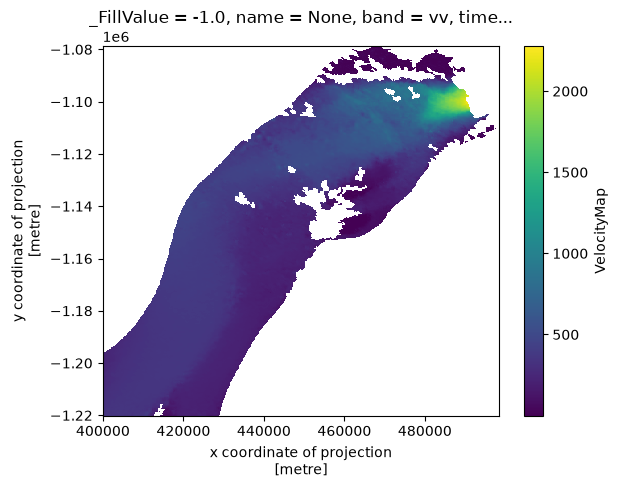

In [17]:
zi_clipped.sel(band='vv').isel(time=79).plot.imshow()